# Real Estate Investment Advisor: Predicting Property Profitability & Future Value

**Dataset:** `india_housing_prices.csv` (250,000 listings, 42 cities, 20 states)  |  **Tools:** pandas, scikit-learn, XGBoost, MLflow, seaborn, Streamlit

**Contents**
1. Setup and data loading
2. Data preprocessing and feature engineering (+ the two target variables)
3. Exploratory data analysis (20 questions)
4. Classification: *Is this a Good Investment?*
5. Regression: *Estimated price after 5 years*
6. MLflow experiment tracking and model registry
7. Prediction for a new property
8. Conclusions and limitations
9. Streamlit application and compatibility verification

> Run this notebook from the project root. Retraining requires `data/raw/india_housing_prices.csv`; the included Streamlit app runs immediately from the packaged artifacts. The app uses a portable scikit-learn inference classifier, so it does not deserialise XGBoost artifacts.


## 1. Setup and data loading

In [1]:
import warnings, json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, mlflow, mlflow.sklearn
from mlflow.models import infer_signature
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, mean_squared_error, mean_absolute_error, r2_score)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep", font_scale=0.95)
%matplotlib inline

ROOT = Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "india_housing_prices.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "india_housing_cleaned.csv"
MODELS_DIR = ROOT / "models_nb"; MODELS_DIR.mkdir(exist_ok=True)
RANDOM_STATE, REFERENCE_YEAR, FORECAST_YEARS = 42, 2025, 5

# ---- Growth-rate assumptions for the 5-year target (dataset has no price history) ----
BASE_GROWTH = 0.060
TIER1 = ["Mumbai","New Delhi","Bangalore","Chennai","Hyderabad","Kolkata","Pune","Ahmedabad","Gurgaon","Noida"]
TIER2 = ["Jaipur","Lucknow","Kochi","Indore","Surat","Nagpur","Bhubaneswar","Coimbatore","Vishakhapatnam","Patna","Bhopal",
         "Mysore","Dwarka","Faridabad","Guwahati","Trivandrum","Dehradun","Raipur","Vijayawada"]
TIER_ADJ = {"Tier-1": 0.010, "Tier-2": 0.015, "Tier-3": 0.005}
TYPE_ADJ = {"Villa": 0.005, "Independent House": 0.0025, "Apartment": 0.0}
STATUS_ADJ = {"Under_Construction": 0.005, "Ready_to_Move": 0.0}
INFRA_MAX_ADJ, AGE_ADJ_PER_YEAR, GROWTH_MIN, GROWTH_MAX, FIXED_RATE = 0.020, -0.0003, 0.04, 0.14, 0.08
TRANSPORT_MAP = {"Low": 0.0, "Medium": 0.5, "High": 1.0}

raw = pd.read_csv(RAW_PATH)
print(raw.shape)
raw.head()

(250000, 23)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [2]:
raw.info()
raw.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  str    
 2   City                            250000 non-null  str    
 3   Locality                        250000 non-null  str    
 4   Property_Type                   250000 non-null  str    
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  str    
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors               

,count,mean,std,min,25%,50%,75%,max
ID,250000.0,125000.500000,72168.927986,1.0,62500.75,125000.50,187500.25,250000.00
BHK,250000.0,2.999396,1.415521,1.0,2.00,3.00,4.00,5.00
Size_in_SqFt,250000.0,2749.813216,1300.606954,500.0,1623.00,2747.00,3874.00,5000.00
Price_in_Lakhs,250000.0,254.586854,141.349921,10.0,132.55,253.87,376.88,500.00
Price_per_SqFt,250000.0,0.130597,0.130747,0.0,0.05,0.09,0.16,0.99
Year_Built,250000.0,2006.520012,9.808575,1990.0,1998.00,2007.00,2015.00,2023.00
Floor_No,250000.0,14.966800,8.948047,0.0,7.00,15.00,23.00,30.00
Total_Floors,250000.0,15.503004,8.671618,1.0,8.00,15.00,23.00,30.00
Age_of_Property,250000.0,18.479988,9.808575,2.0,10.00,18.00,27.00,35.00
Nearby_Schools,250000.0,5.499860,2.878639,1.0,3.00,5.00,8.00,10.00


## 2. Data preprocessing and feature engineering

Steps: missing values and duplicates, consistency checks (age, floors), price per sq ft in INR, IQR outlier flags (flagged, not dropped), engineered features, then the two targets.

**Target 1: `Good_Investment`** = meets at least 3 of 5 criteria: price/sq ft ≤ city median, price ≤ city median, BHK ≥ 3, ready to move, infrastructure score ≥ 0.5.

**Target 2: `Future_Price_5Y_Lakhs`** = `Price × (1 + r)^5`, where the annual growth rate `r` is feature-based (6% base + city tier, property type, availability, infrastructure, age adjustments; clipped to 4–14%). The dataset is a single snapshot, so these rates are documented assumptions, not estimates.

In [3]:
df = raw.copy()
qa = {"raw_rows": len(df)}

# 1. Missing values and duplicates
qa["missing_values"] = int(df.isna().sum().sum())
for c in df.select_dtypes("number"): df[c] = df[c].fillna(df[c].median())
for c in df.select_dtypes(exclude="number"): df[c] = df[c].fillna(df[c].mode().iloc[0])
qa["duplicates"] = int(df.duplicated(subset=df.columns.drop("ID")).sum())
df = df.drop_duplicates(subset=df.columns.drop("ID")).reset_index(drop=True)

# 2. Consistency checks
age_calc = REFERENCE_YEAR - df["Year_Built"]
qa["age_mismatch"] = int((age_calc != df["Age_of_Property"]).sum()); df["Age_of_Property"] = age_calc
bad_floor = df["Floor_No"] > df["Total_Floors"]
qa["floor_gt_total"] = int(bad_floor.sum()); qa["floor_gt_total_pct"] = round(100 * bad_floor.mean(), 2)
df["Floor_Data_Corrected"] = bad_floor.astype(int)
df["Total_Floors"] = np.maximum(df["Total_Floors"], df["Floor_No"])
df["Price_per_SqFt_INR"] = df["Price_in_Lakhs"] * 1e5 / df["Size_in_SqFt"]

# 3. Outliers (IQR) - flagged, not removed
def iqr_flag(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - k * i) | (s > q3 + k * i)).astype(int)
df["Outlier_PPSF"], df["Outlier_Size"], df["Outlier_Price"] = (iqr_flag(df["Price_per_SqFt_INR"]), iqr_flag(df["Size_in_SqFt"]), iqr_flag(df["Price_in_Lakhs"]))
qa["outliers"] = {c: int(df[c].sum()) for c in ["Outlier_PPSF", "Outlier_Size", "Outlier_Price"]}

# 4. Feature engineering
df["City_Tier"] = df["City"].map(lambda c: "Tier-1" if c in TIER1 else ("Tier-2" if c in TIER2 else "Tier-3"))
amen = df["Amenities"].fillna("").str.split(r",\s*")
for a in ["Gym", "Pool", "Clubhouse", "Playground", "Garden"]: df[f"Has_{a}"] = amen.apply(lambda x: int(a in x))
df["Amenity_Count"] = amen.apply(lambda x: len([i for i in x if i]))
df["Is_Ready_To_Move"] = (df["Availability_Status"] == "Ready_to_Move").astype(int)
df["Has_Parking"] = (df["Parking_Space"] == "Yes").astype(int)
df["Has_Security"] = (df["Security"] == "Yes").astype(int)
df["Transport_Score"] = df["Public_Transport_Accessibility"].map(TRANSPORT_MAP)
df["School_Density_Score"] = df["Nearby_Schools"] / df["Nearby_Schools"].max()
df["Hospital_Density_Score"] = df["Nearby_Hospitals"] / df["Nearby_Hospitals"].max()
df["Infrastructure_Score"] = (df["School_Density_Score"] + df["Hospital_Density_Score"] + df["Transport_Score"]) / 3
df["Floor_Ratio"] = df["Floor_No"] / df["Total_Floors"]
df["SqFt_per_BHK"] = df["Size_in_SqFt"] / df["BHK"]
df["Log_Price"], df["Log_Size"] = np.log1p(df["Price_in_Lakhs"]), np.log1p(df["Size_in_SqFt"])
df["City_Median_PPSF"] = df.groupby("City")["Price_per_SqFt_INR"].transform("median")
df["City_Median_Price"] = df.groupby("City")["Price_in_Lakhs"].transform("median")
df["PPSF_vs_City_Median"] = df["Price_per_SqFt_INR"] / df["City_Median_PPSF"]

# 5. Target 1: Good_Investment
df["Crit_Value_PPSF"] = (df["Price_per_SqFt_INR"] <= df["City_Median_PPSF"]).astype(int)
df["Crit_Value_Price"] = (df["Price_in_Lakhs"] <= df["City_Median_Price"]).astype(int)
df["Crit_Family_Size"] = (df["BHK"] >= 3).astype(int)
df["Crit_Ready"] = df["Is_Ready_To_Move"]
df["Crit_Infrastructure"] = (df["Infrastructure_Score"] >= 0.5).astype(int)
df["Investment_Score"] = df[[c for c in df.columns if c.startswith("Crit_")]].sum(axis=1)
df["Good_Investment"] = (df["Investment_Score"] >= 3).astype(int)

# 6. Target 2: Future price after 5 years
r = (BASE_GROWTH + df["City_Tier"].map(TIER_ADJ) + df["Property_Type"].map(TYPE_ADJ) + df["Availability_Status"].map(STATUS_ADJ)
     + INFRA_MAX_ADJ * df["Infrastructure_Score"] + AGE_ADJ_PER_YEAR * df["Age_of_Property"]).clip(GROWTH_MIN, GROWTH_MAX)
df["Annual_Growth_Rate"] = r
df["Future_Price_5Y_Lakhs"] = df["Price_in_Lakhs"] * (1 + r) ** FORECAST_YEARS
df["Fixed8_Future_Price_Lakhs"] = df["Price_in_Lakhs"] * (1 + FIXED_RATE) ** FORECAST_YEARS

PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_PATH, index=False)
print(json.dumps(qa, indent=2)); print("Good-investment rate:", round(df["Good_Investment"].mean(), 4), "| columns:", df.shape[1])
print("Annual growth rate summary:"); print((df["Annual_Growth_Rate"].describe() * 100).round(2).to_string())

{
  "raw_rows": 250000,
  "missing_values": 0,
  "duplicates": 0,
  "age_mismatch": 0,
  "floor_gt_total": 116304,
  "floor_gt_total_pct": 46.52,
  "outliers": {
    "Outlier_PPSF": 19723,
    "Outlier_Size": 0,
    "Outlier_Price": 0
  }
}
Good-investment rate: 0.5598 | columns: 59
Annual growth rate summary:
count    25000000.00
mean            8.08
std             0.73
min             5.58
25%             7.58
50%             8.10
75%             8.60
max            10.44


In [4]:
df[["City","Property_Type","BHK","Size_in_SqFt","Price_in_Lakhs","Price_per_SqFt_INR","Infrastructure_Score","Investment_Score","Good_Investment","Annual_Growth_Rate","Future_Price_5Y_Lakhs"]].head(8)

,City,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_INR,Infrastructure_Score,Investment_Score,Good_Investment,Annual_Growth_Rate,Future_Price_5Y_Lakhs
0,Chennai,Apartment,1,4740,489.76,10332.489451,0.766667,2,0,0.074833,702.568938
1,Pune,Independent House,3,2364,195.52,8270.727580,0.300000,3,1,0.078400,285.161299
2,Ludhiana,Apartment,2,3642,183.79,5046.403075,0.566667,4,1,0.067933,255.295165
3,Jodhpur,Independent House,2,2741,300.29,10955.490697,0.733333,2,0,0.071967,425.057100
4,Jaipur,Villa,4,4823,182.90,3792.245490,0.433333,4,1,0.081767,270.945337
5,Durgapur,Apartment,4,3500,135.28,3865.142857,0.466667,4,1,0.072833,192.262634
6,Coimbatore,Independent House,3,4826,318.12,6591.794447,0.633333,3,1,0.092467,495.030488
7,Bilaspur,Independent House,5,4252,141.39,3325.258702,1.000000,4,1,0.091300,218.846432


## 3. Exploratory data analysis (20 questions)

Charts appear inline. **Reading note:** in this dataset, price is almost independent of size, location and facilities (the data looks synthetically generated), so many EDA answers are "no meaningful relationship". Also, the dataset has no crime-rate column, so infrastructure score is used as the proxy.

In [5]:
PPSF = "Price_per_SqFt_INR"
F = {}   # findings collected for each question
def show(): plt.tight_layout(); plt.show()
def corr_p(a, b): return round(float(df[a].corr(df[b])), 4)

### Q1-Q5: Price and size analysis

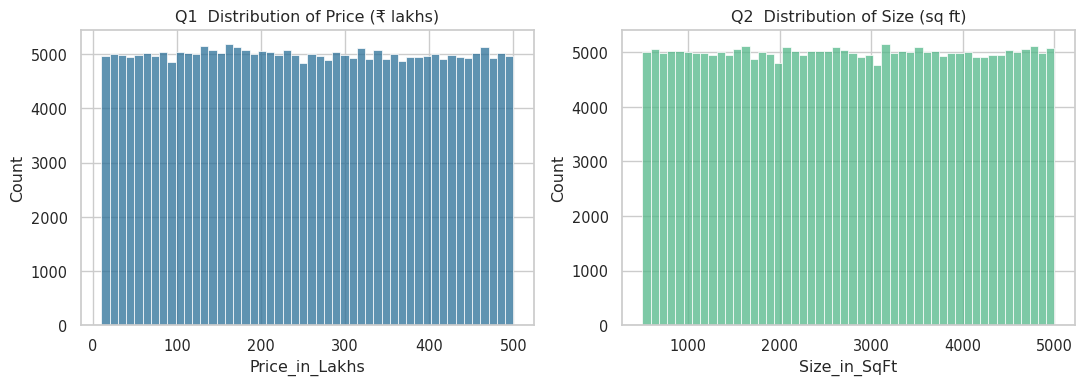

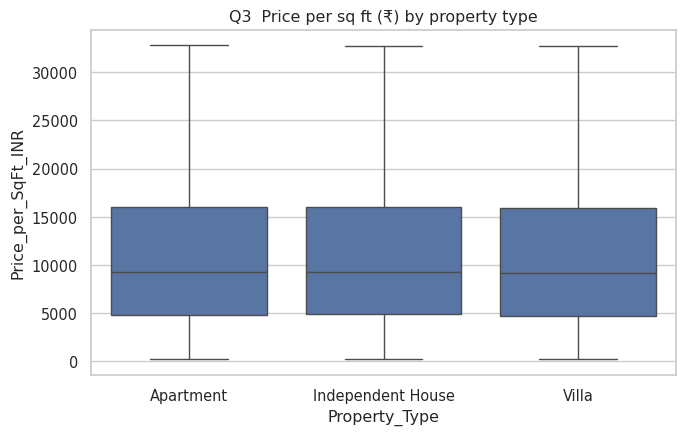

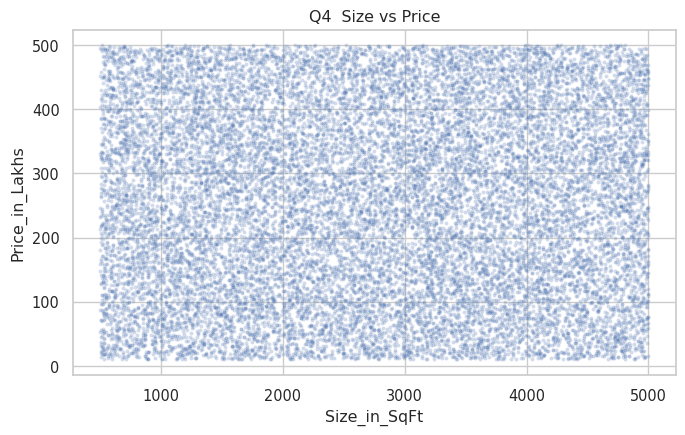

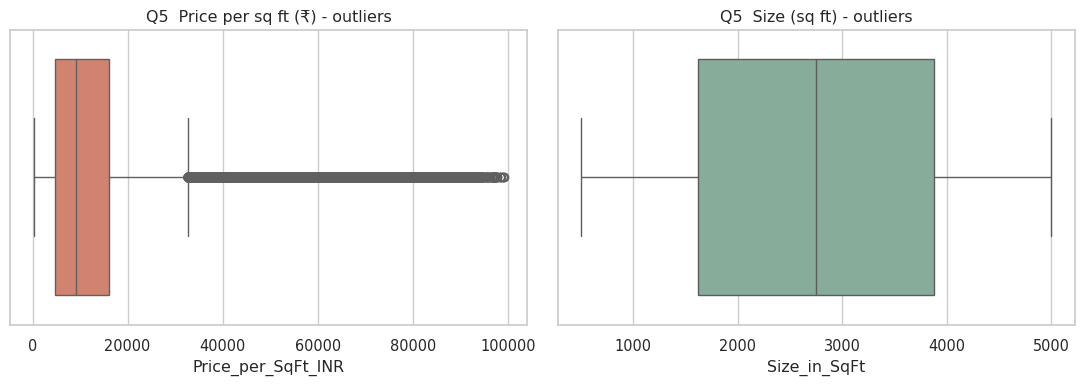

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Price_in_Lakhs"], bins=50, ax=ax[0], color="#2a6f97"); ax[0].set_title("Q1  Distribution of Price (₹ lakhs)")
sns.histplot(df["Size_in_SqFt"], bins=50, ax=ax[1], color="#52b788"); ax[1].set_title("Q2  Distribution of Size (sq ft)")
show()
F["Q1"] = df["Price_in_Lakhs"].describe().round(2).to_dict()
F["Q2"] = df["Size_in_SqFt"].describe().round(2).to_dict()

plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="Property_Type", y=PPSF, showfliers=False); plt.title("Q3  Price per sq ft (₹) by property type")
show()
F["Q3"] = df.groupby("Property_Type")[PPSF].agg(["mean", "median"]).round(0).to_dict()

s = df.sample(20000, random_state=1)
plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=s, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=.25, s=8); plt.title("Q4  Size vs Price")
show()
F["Q4"] = {"pearson_size_price": corr_p("Size_in_SqFt", "Price_in_Lakhs"),
           "pearson_size_ppsf": corr_p("Size_in_SqFt", PPSF)}

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=df[PPSF], ax=ax[0], color="#e07a5f"); ax[0].set_title("Q5  Price per sq ft (₹) - outliers")
sns.boxplot(x=df["Size_in_SqFt"], ax=ax[1], color="#81b29a"); ax[1].set_title("Q5  Size (sq ft) - outliers")
show()
F["Q5"] = {"ppsf_outliers_iqr": int(df["Outlier_PPSF"].sum()), "ppsf_outlier_pct": round(100 * df["Outlier_PPSF"].mean(), 2),
           "size_outliers": int(df["Outlier_Size"].sum()), "ppsf_p50": round(df[PPSF].median()), "ppsf_p99": round(df[PPSF].quantile(.99)),
           "ppsf_max": round(df[PPSF].max())}

### Q6-Q10: Location-based analysis

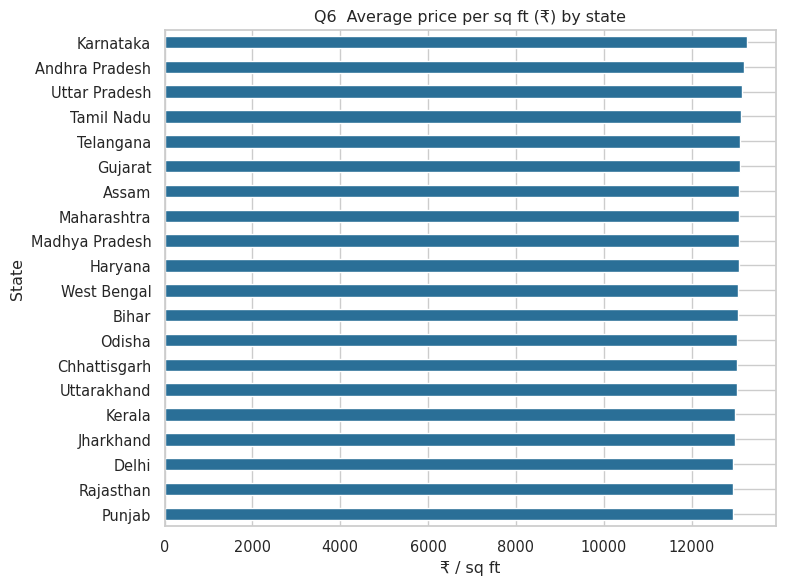

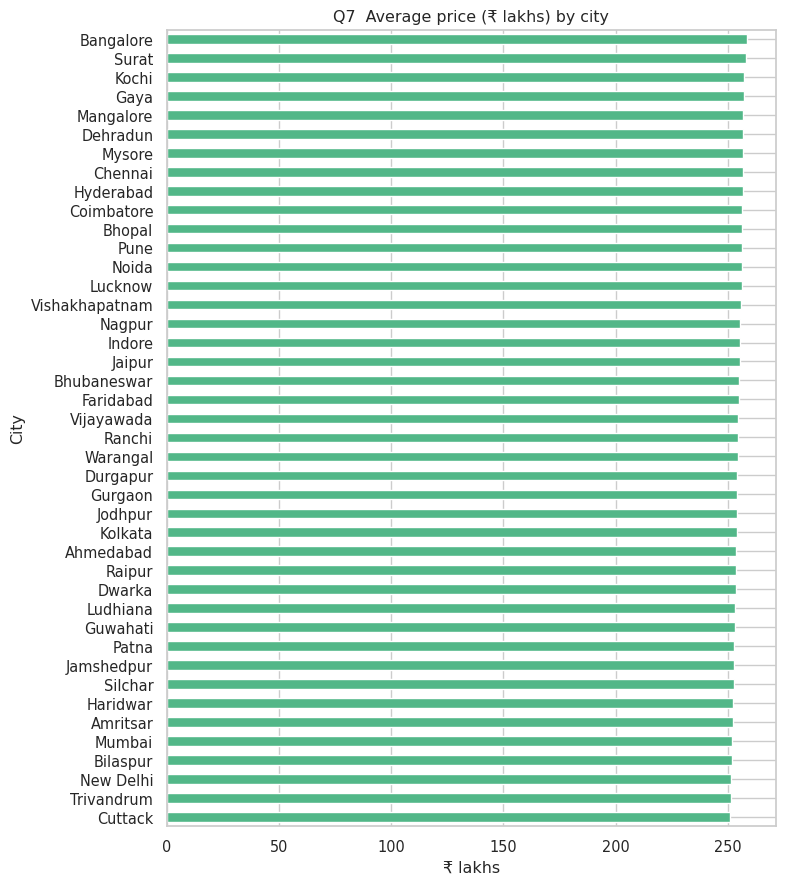

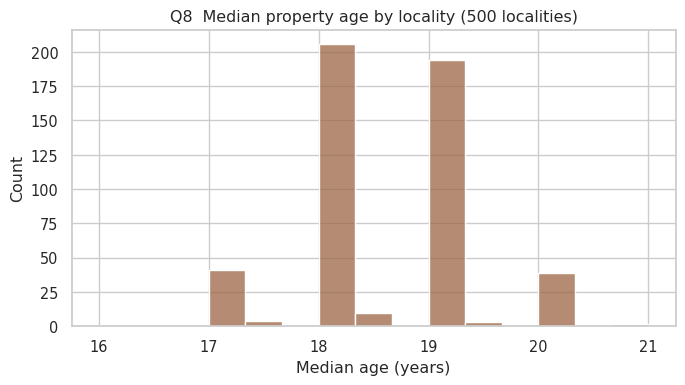

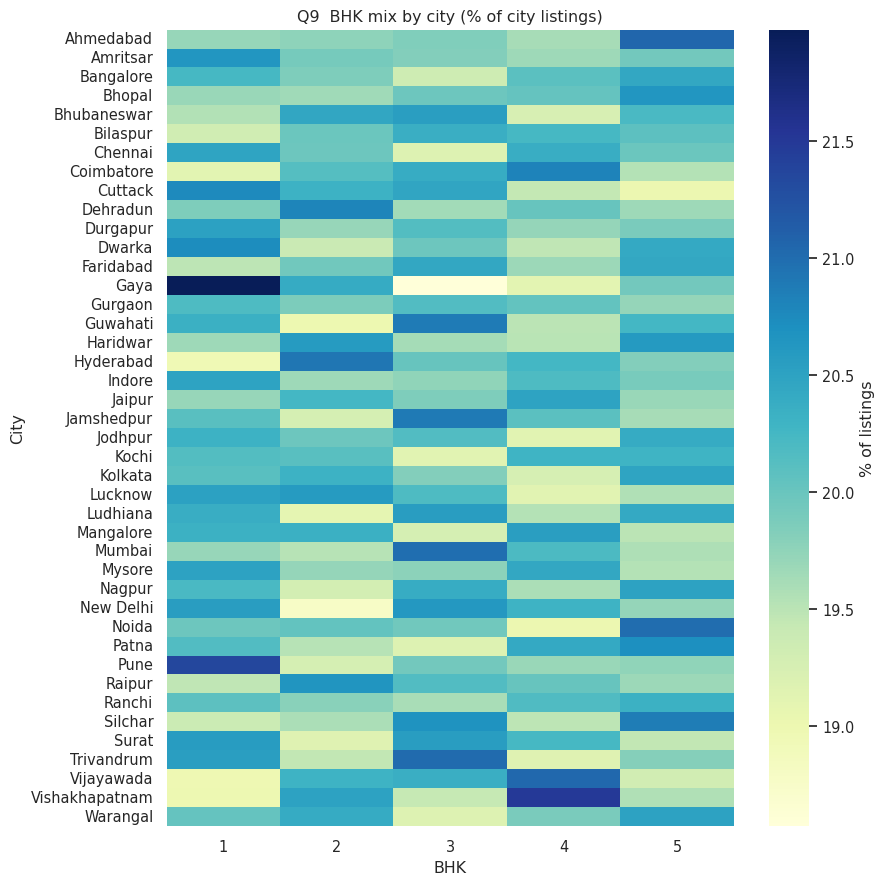

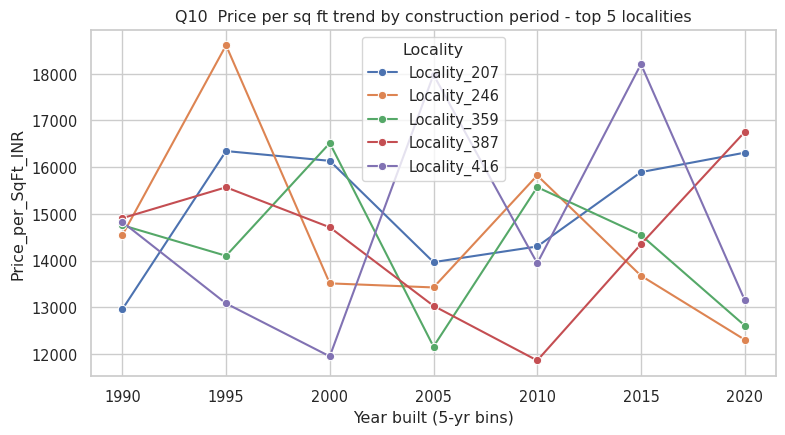

In [7]:
st = df.groupby("State")[PPSF].mean().sort_values()
plt.figure(figsize=(8, 6)); st.plot.barh(color="#2a6f97"); plt.title("Q6  Average price per sq ft (₹) by state"); plt.xlabel("₹ / sq ft")
show()
F["Q6"] = {"highest": [st.index[-1], round(st.iloc[-1])], "lowest": [st.index[0], round(st.iloc[0])], "spread_pct": round(100 * (st.max() / st.min() - 1), 2)}

ct = df.groupby("City")["Price_in_Lakhs"].mean().sort_values()
plt.figure(figsize=(8, 9)); ct.plot.barh(color="#52b788"); plt.title("Q7  Average price (₹ lakhs) by city"); plt.xlabel("₹ lakhs")
show()
F["Q7"] = {"highest": [ct.index[-1], round(ct.iloc[-1], 1)], "lowest": [ct.index[0], round(ct.iloc[0], 1)], "spread_pct": round(100 * (ct.max() / ct.min() - 1), 2)}

la = df.groupby("Locality")["Age_of_Property"].median()
plt.figure(figsize=(7, 4)); sns.histplot(la, bins=15, color="#9c6644"); plt.title("Q8  Median property age by locality (500 localities)"); plt.xlabel("Median age (years)")
show()
F["Q8"] = {"min": float(la.min()), "max": float(la.max()), "median": float(la.median()),
           "top5_oldest": la.sort_values(ascending=False).head(5).to_dict()}

bc = pd.crosstab(df["City"], df["BHK"], normalize="index") * 100
plt.figure(figsize=(9, 9)); sns.heatmap(bc, annot=False, cmap="YlGnBu", cbar_kws={"label": "% of listings"}); plt.title("Q9  BHK mix by city (% of city listings)")
show()
F["Q9"] = {"overall_bhk_pct": (df["BHK"].value_counts(normalize=True).sort_index() * 100).round(1).to_dict(),
           "max_city_deviation_pp": round(float((bc - bc.mean()).abs().max().max()), 2)}

loc_top = df.groupby("Locality")[PPSF].mean().nlargest(5).index.tolist()
d5 = df[df["Locality"].isin(loc_top)].copy()
d5["Build_Period"] = (d5["Year_Built"] // 5) * 5
tr = d5.groupby(["Build_Period", "Locality"])[PPSF].mean().reset_index()
plt.figure(figsize=(8, 4.5)); sns.lineplot(data=tr, x="Build_Period", y=PPSF, hue="Locality", marker="o")
plt.title("Q10  Price per sq ft trend by construction period - top 5 localities"); plt.xlabel("Year built (5-yr bins)")
show()
F["Q10"] = {"top5_localities": loc_top, "avg_ppsf": df[df["Locality"].isin(loc_top)].groupby("Locality")[PPSF].mean().round(0).to_dict(),
            "top5_vs_overall_gap_pct": round(100 * (df[df["Locality"].isin(loc_top)][PPSF].mean() / df[PPSF].mean() - 1), 2)}

### Q11-Q15: Feature relationships and correlation

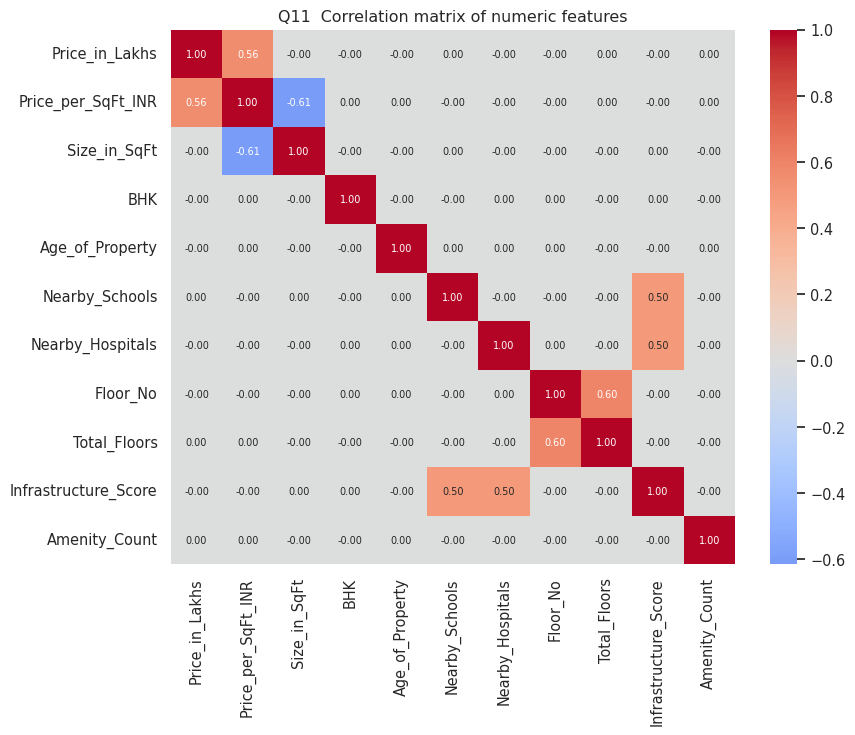

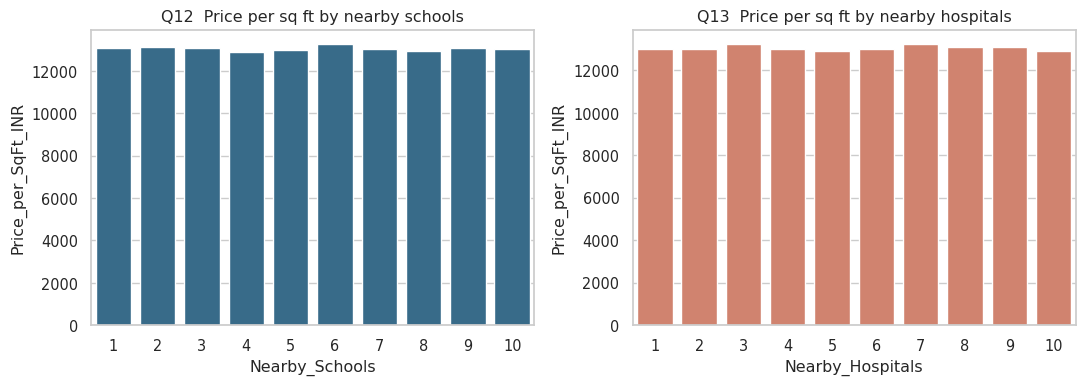

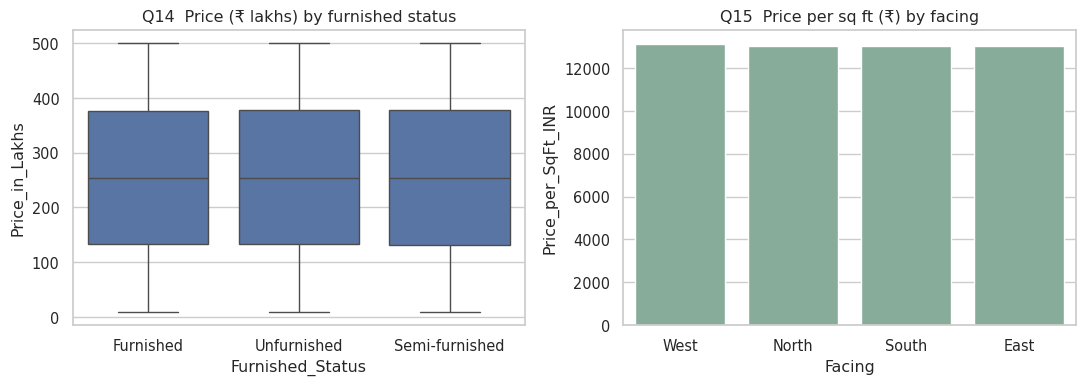

In [8]:
num = ["Price_in_Lakhs", PPSF, "Size_in_SqFt", "BHK", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals", "Floor_No", "Total_Floors", "Infrastructure_Score", "Amenity_Count"]
cm = df[num].corr()
plt.figure(figsize=(9, 7.5)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7}); plt.title("Q11  Correlation matrix of numeric features")
show()
off = cm.where(~np.eye(len(cm), dtype=bool)).abs().stack().sort_values(ascending=False)
F["Q11"] = {"top_pairs": {f"{a} | {b}": round(float(cm.loc[a, b]), 3) for (a, b) in off.index[:6:2]},
            "price_vs_ppsf": round(float(cm.loc["Price_in_Lakhs", PPSF]), 3),
            "size_vs_ppsf": round(float(cm.loc["Size_in_SqFt", PPSF]), 3)}

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=df, x="Nearby_Schools", y=PPSF, ax=ax[0], color="#2a6f97", errorbar=None); ax[0].set_title("Q12  Price per sq ft by nearby schools")
sns.barplot(data=df, x="Nearby_Hospitals", y=PPSF, ax=ax[1], color="#e07a5f", errorbar=None); ax[1].set_title("Q13  Price per sq ft by nearby hospitals")
show()
F["Q12"] = {"pearson_schools_ppsf": corr_p("Nearby_Schools", PPSF)}
F["Q13"] = {"pearson_hospitals_ppsf": corr_p("Nearby_Hospitals", PPSF)}

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="Furnished_Status", y="Price_in_Lakhs", ax=ax[0], showfliers=False); ax[0].set_title("Q14  Price (₹ lakhs) by furnished status")
sns.barplot(data=df, x="Facing", y=PPSF, ax=ax[1], errorbar=None, color="#81b29a"); ax[1].set_title("Q15  Price per sq ft (₹) by facing")
show()
F["Q14"] = df.groupby("Furnished_Status")["Price_in_Lakhs"].agg(["mean", "median"]).round(1).to_dict()
F["Q15"] = df.groupby("Facing")[PPSF].mean().round(0).to_dict()

### Q16-Q20: Investment, amenities and ownership

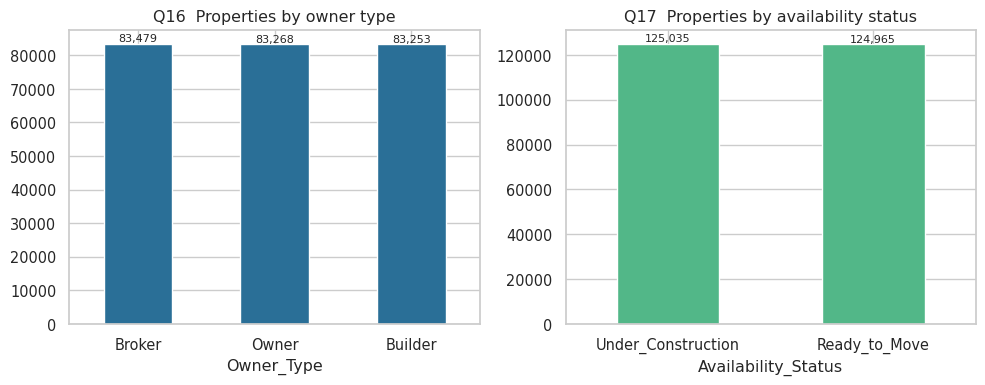

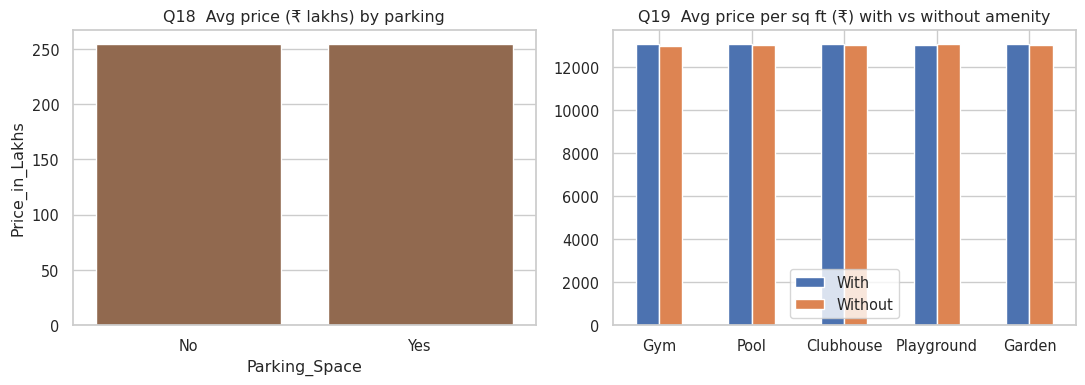

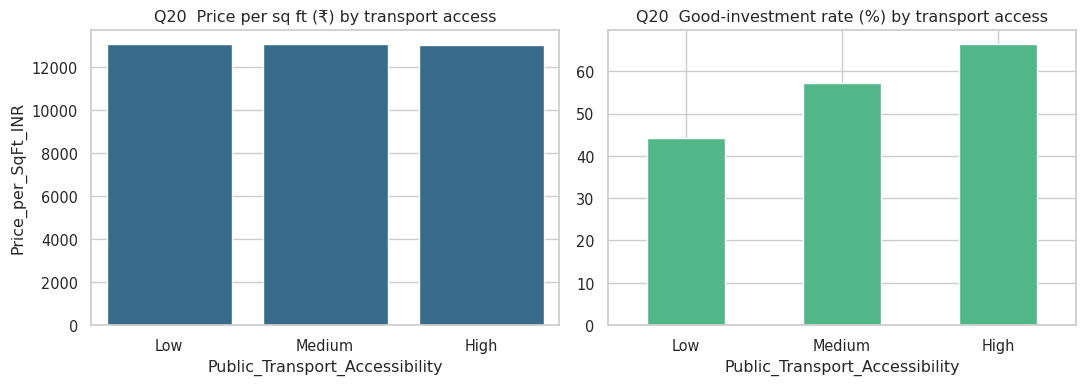

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df["Owner_Type"].value_counts().plot.bar(ax=ax[0], color="#2a6f97", rot=0); ax[0].set_title("Q16  Properties by owner type")
df["Availability_Status"].value_counts().plot.bar(ax=ax[1], color="#52b788", rot=0); ax[1].set_title("Q17  Properties by availability status")
for a in ax:
    for p in a.patches: a.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
show()
F["Q16"] = df["Owner_Type"].value_counts().to_dict()
F["Q17"] = df["Availability_Status"].value_counts().to_dict()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=df, x="Parking_Space", y="Price_in_Lakhs", ax=ax[0], errorbar=None, color="#9c6644"); ax[0].set_title("Q18  Avg price (₹ lakhs) by parking")
am = pd.DataFrame({a: [df.loc[df[f"Has_{a}"] == 1, PPSF].mean(), df.loc[df[f"Has_{a}"] == 0, PPSF].mean()] for a in ["Gym", "Pool", "Clubhouse", "Playground", "Garden"]}, index=["With", "Without"]).T
am.plot.bar(ax=ax[1], rot=0); ax[1].set_title("Q19  Avg price per sq ft (₹) with vs without amenity")
show()
F["Q18"] = df.groupby("Parking_Space")["Price_in_Lakhs"].mean().round(2).to_dict()
F["Q19"] = {"ppsf_with_vs_without_pct": ((am["With"] / am["Without"] - 1) * 100).round(2).to_dict(),
            "amenity_count_ppsf_corr": corr_p("Amenity_Count", PPSF)}

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=df, x="Public_Transport_Accessibility", y=PPSF, order=["Low", "Medium", "High"], ax=ax[0], errorbar=None, color="#2a6f97"); ax[0].set_title("Q20  Price per sq ft (₹) by transport access")
gi = df.groupby("Public_Transport_Accessibility")["Good_Investment"].mean().reindex(["Low", "Medium", "High"]) * 100
gi.plot.bar(ax=ax[1], rot=0, color="#52b788"); ax[1].set_title("Q20  Good-investment rate (%) by transport access")
show()
F["Q20"] = {"ppsf": df.groupby("Public_Transport_Accessibility")[PPSF].mean().round(0).to_dict(), "good_investment_pct": gi.round(2).to_dict()}

### Extra analyses from the brief (city, area, infrastructure)

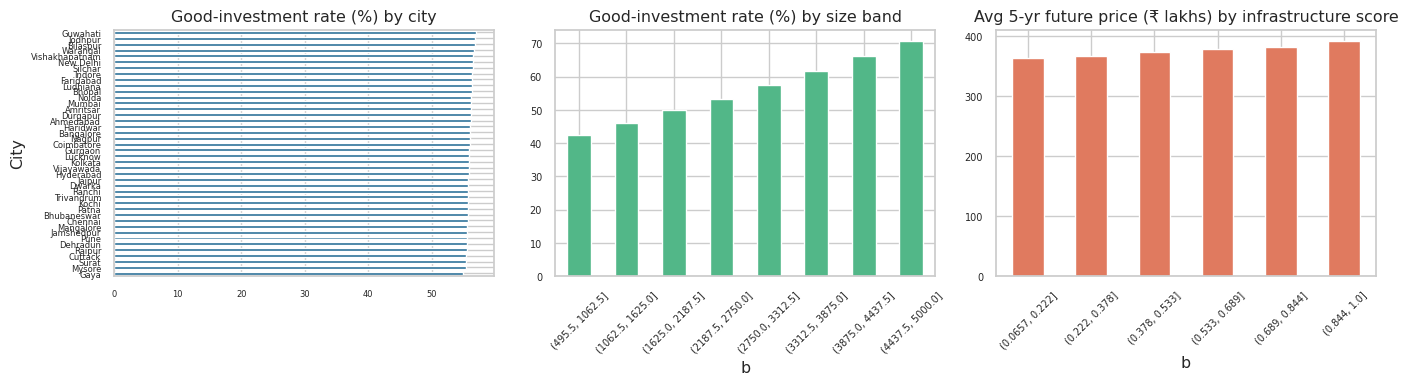

In [10]:
cg = df.groupby("City_Tier")[["Annual_Growth_Rate"]].mean().mul(100).round(2)
F["Tier_growth_pct"] = cg["Annual_Growth_Rate"].to_dict()
F["GoodInv_rate_by_city_top5"] = (df.groupby("City")["Good_Investment"].mean().nlargest(5) * 100).round(1).to_dict()
F["GoodInv_rate_overall_pct"] = round(100 * df["Good_Investment"].mean(), 2)
F["Area_vs_good_investment_corr"] = corr_p("Size_in_SqFt", "Good_Investment")
F["Infra_vs_future_price_corr"] = corr_p("Infrastructure_Score", "Future_Price_5Y_Lakhs")
F["Infra_vs_ppsf_corr"] = corr_p("Infrastructure_Score", PPSF)
F["Area_vs_growth_corr"] = corr_p("Size_in_SqFt", "Annual_Growth_Rate")
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
(df.groupby("City")["Good_Investment"].mean().sort_values().mul(100)).plot.barh(ax=ax[0], color="#2a6f97", fontsize=6); ax[0].set_title("Good-investment rate (%) by city")
df.assign(b=pd.cut(df["Size_in_SqFt"], 8)).groupby("b", observed=True)["Good_Investment"].mean().mul(100).plot.bar(ax=ax[1], color="#52b788", rot=45, fontsize=7); ax[1].set_title("Good-investment rate (%) by size band")
df.assign(b=pd.cut(df["Infrastructure_Score"], 6)).groupby("b", observed=True)["Future_Price_5Y_Lakhs"].mean().plot.bar(ax=ax[2], color="#e07a5f", rot=45, fontsize=7); ax[2].set_title("Avg 5-yr future price (₹ lakhs) by infrastructure score")
show()

# Crime-rate: not present in dataset -> documented limitation
F["Crime_rate_note"] = "No crime-rate column exists in india_housing_prices.csv; analysis not possible. Infrastructure proxy used instead."

# Key insight: are features informative about price at all?
X = df[["Size_in_SqFt", "BHK", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals", "Floor_No", "Amenity_Count", "Transport_Score"]]
F["Max_abs_corr_with_price"] = round(float(X.corrwith(df["Price_in_Lakhs"]).abs().max()), 4)
F["Locality_repeats_across_cities"] = int(df.groupby("Locality")["City"].nunique().median())

In [11]:
F_out = {k: v for k, v in F.items() if k.startswith("Q")}
for k in sorted(F_out, key=lambda x: int(x[1:])): print(k, "->", F_out[k])
print()
for k in [k for k in F if not k.startswith("Q")]: print(k, "->", F[k])

Q1 -> {'count': 250000.0, 'mean': 254.59, 'std': 141.35, 'min': 10.0, '25%': 132.55, '50%': 253.87, '75%': 376.88, 'max': 500.0}
Q2 -> {'count': 250000.0, 'mean': 2749.81, 'std': 1300.61, 'min': 500.0, '25%': 1623.0, '50%': 2747.0, '75%': 3874.0, 'max': 5000.0}
Q3 -> {'mean': {'Apartment': 13047.0, 'Independent House': 13102.0, 'Villa': 13026.0}, 'median': {'Apartment': 9245.0, 'Independent House': 9305.0, 'Villa': 9190.0}}
Q4 -> {'pearson_size_price': -0.0025, 'pearson_size_ppsf': -0.6146}
Q5 -> {'ppsf_outliers_iqr': 19723, 'ppsf_outlier_pct': np.float64(7.89), 'size_outliers': 0, 'ppsf_p50': 9245, 'ppsf_p99': 65823, 'ppsf_max': 99182}
Q6 -> {'highest': ['Karnataka', 13252], 'lowest': ['Punjab', 12931], 'spread_pct': np.float64(2.48)}
Q7 -> {'highest': ['Bangalore', np.float64(258.5)], 'lowest': ['Cuttack', np.float64(250.8)], 'spread_pct': np.float64(3.06)}
Q8 -> {'min': 16.0, 'max': 21.0, 'median': 18.0, 'top5_oldest': {'Locality_72': 21.0, 'Locality_403': 21.0, 'Locality_90': 20.0,

## 4. Classification: Is this a Good Investment?

Split: 70% train / 15% validation / 15% test (stratified). Models are **selected on validation F1**; the test set is reported once. Features are scaled (numeric) and one-hot encoded (categorical) inside a pipeline. `Locality` is excluded because the same 500 labels repeat in every city and carry no stable meaning.

In [12]:
NUM_FEATURES = ["BHK","Size_in_SqFt","Price_in_Lakhs","Price_per_SqFt_INR","Age_of_Property","Floor_No","Total_Floors","Floor_Ratio",
    "Nearby_Schools","Nearby_Hospitals","Transport_Score","School_Density_Score","Hospital_Density_Score","Infrastructure_Score",
    "Amenity_Count","Has_Gym","Has_Pool","Has_Clubhouse","Has_Playground","Has_Garden","Has_Parking","Has_Security",
    "Is_Ready_To_Move","SqFt_per_BHK","City_Median_PPSF","City_Median_Price","PPSF_vs_City_Median"]
CAT_FEATURES = ["Property_Type","Furnished_Status","Facing","Owner_Type","City","City_Tier"]
ALL_FEATURES = NUM_FEATURES + CAT_FEATURES
CONTEXT_FEATURES = ["City_Median_PPSF","City_Median_Price","PPSF_vs_City_Median"]

def split_data(d, target, stratify=False):
    s = d[target] if stratify else None
    tr, tmp = train_test_split(d, test_size=0.30, random_state=RANDOM_STATE, stratify=s)
    s2 = tmp[target] if stratify else None
    va, te = train_test_split(tmp, test_size=0.50, random_state=RANDOM_STATE, stratify=s2)
    return tr, va, te

def make_pipeline(model, num_cols=None, cat_cols=None):
    prep = ColumnTransformer([("num", StandardScaler(), num_cols or NUM_FEATURES),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols or CAT_FEATURES)])
    return Pipeline([("prep", prep), ("model", model)])

def grouped_importance(pipe, X, y, scoring, n=15000):
    idx = X.sample(min(n, len(X)), random_state=RANDOM_STATE).index
    r = permutation_importance(pipe, X.loc[idx], y.loc[idx], scoring=scoring, n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
    return pd.Series(r.importances_mean, index=X.columns).sort_values(ascending=False)

def plot_importance(imp, title, top=15):
    s = imp.head(top)[::-1]
    plt.figure(figsize=(7.5, 5)); plt.barh(s.index, s.values, color="#2a6f97"); plt.title(title); plt.xlabel("Permutation importance"); show()

# MLflow (separate local store for the notebook)
(ROOT / "mlflow").mkdir(exist_ok=True)
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow' / 'mlflow_notebook.db').as_posix()}")
def get_experiment(name, sub):
    if mlflow.get_experiment_by_name(name) is None:
        mlflow.create_experiment(name, artifact_location=f"file://{(ROOT / 'mlflow' / 'artifacts_nb' / sub).as_posix()}")
    mlflow.set_experiment(name)

TARGET = "Good_Investment"
tr, va, te = split_data(df, TARGET, stratify=True)
Xtr, ytr, Xva, yva, Xte, yte = tr[ALL_FEATURES], tr[TARGET], va[ALL_FEATURES], va[TARGET], te[ALL_FEATURES], te[TARGET]
print(f"train {len(tr):,} | validation {len(va):,} | test {len(te):,} | positive rate {df[TARGET].mean():.3f}")

train 175,000 | validation 37,500 | test 37,500 | positive rate 0.560


In [13]:
def clf_metrics(pipe, X, y, prefix):
    p, pr = pipe.predict(X), pipe.predict_proba(X)[:, 1]
    return {f"{prefix}_accuracy": accuracy_score(y, p), f"{prefix}_precision": precision_score(y, p), f"{prefix}_recall": recall_score(y, p),
            f"{prefix}_f1": f1_score(y, p), f"{prefix}_roc_auc": roc_auc_score(y, pr)}

get_experiment("RealEstate_Classification_GoodInvestment_NB", "classification")

# XGBoost hyper-parameter search on a 40k subsample (3-fold CV, F1)
sub = tr.sample(40000, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    make_pipeline(XGBClassifier(tree_method="hist", n_jobs=1, random_state=RANDOM_STATE, eval_metric="logloss")),
    {"model__n_estimators": [200, 300, 400], "model__max_depth": [4, 6, 8], "model__learning_rate": [0.05, 0.1, 0.2],
     "model__subsample": [0.8, 1.0], "model__colsample_bytree": [0.6, 0.8, 1.0], "model__min_child_weight": [1, 5]},
    n_iter=6, scoring="f1", cv=3, random_state=RANDOM_STATE, n_jobs=1)
search.fit(sub[ALL_FEATURES], sub[TARGET])
best_xgb = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("Best XGB params:", best_xgb, "| CV F1:", round(search.best_score_, 4))

candidates = {
    "Baseline_MajorityClass": DummyClassifier(strategy="most_frequent"),
    "LogisticRegression": LogisticRegression(max_iter=500, n_jobs=1),
    "RandomForest": RandomForestClassifier(n_estimators=80, max_depth=14, min_samples_leaf=10, max_features=0.5, n_jobs=1, random_state=RANDOM_STATE),
    "XGBoost_Tuned": XGBClassifier(**best_xgb, tree_method="hist", n_jobs=1, random_state=RANDOM_STATE, eval_metric="logloss")}
clf_results, clf_fitted, clf_runs = {}, {}, {}
for name, model in candidates.items():
    with mlflow.start_run(run_name=name) as run:
        t0 = time.time(); pipe = make_pipeline(model).fit(Xtr, ytr)
        m = {**clf_metrics(pipe, Xva, yva, "val"), **clf_metrics(pipe, Xte, yte, "test"), "fit_seconds": time.time() - t0}
        mlflow.log_params({"model": name, "n_features": len(ALL_FEATURES), "train_rows": len(tr)}); mlflow.log_metrics(m); mlflow.set_tag("task", "classification")
        clf_results[name], clf_fitted[name], clf_runs[name] = m, pipe, run.info.run_id
res = pd.DataFrame(clf_results).T[["val_f1", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc", "fit_seconds"]].round(4)
res

2026/10/25 17:13:53 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/25 17:13:53 INFO mlflow.store.db.utils: Updating database tables


Best XGB params: {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.2, 'colsample_bytree': 0.8} | CV F1: 0.9986


,val_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,fit_seconds
Baseline_MajorityClass,0.7178,0.5598,0.5598,1.0000,0.7178,0.5000,0.9619
LogisticRegression,0.9031,0.8894,0.8984,0.9046,0.9015,0.9635,1.3384
RandomForest,0.9989,0.9989,0.9989,0.9991,0.9990,1.0000,50.1679
XGBoost_Tuned,0.9995,0.9995,0.9995,0.9997,0.9996,1.0000,7.9180


Selected model (validation F1): XGBoost_Tuned


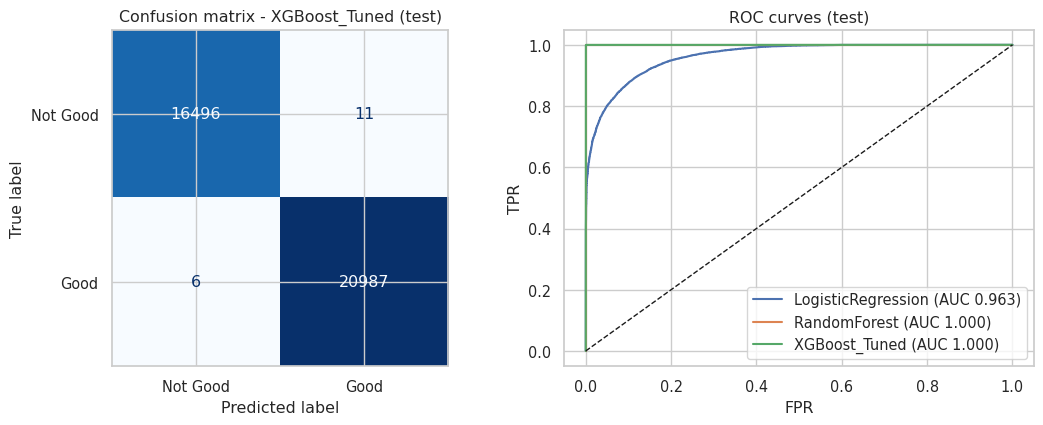

Errors on 37,500 test rows: 11 false positives, 6 false negatives


In [14]:
best_clf = max((k for k in clf_results if not k.startswith("Baseline")), key=lambda k: clf_results[k]["val_f1"])
pipe_clf = clf_fitted[best_clf]; print("Selected model (validation F1):", best_clf)
pred, proba = pipe_clf.predict(Xte), pipe_clf.predict_proba(Xte)[:, 1]
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ConfusionMatrixDisplay(cm, display_labels=["Not Good", "Good"]).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d"); ax[0].set_title(f"Confusion matrix - {best_clf} (test)")
for n_, p_ in clf_fitted.items():
    if n_.startswith("Baseline"): continue
    fpr, tpr, _ = roc_curve(yte, p_.predict_proba(Xte)[:, 1]); ax[1].plot(fpr, tpr, label=f"{n_} (AUC {clf_results[n_]['test_roc_auc']:.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("ROC curves (test)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(loc="lower right"); show()
print(f"Errors on {len(yte):,} test rows: {cm[0,1]} false positives, {cm[1,0]} false negatives")

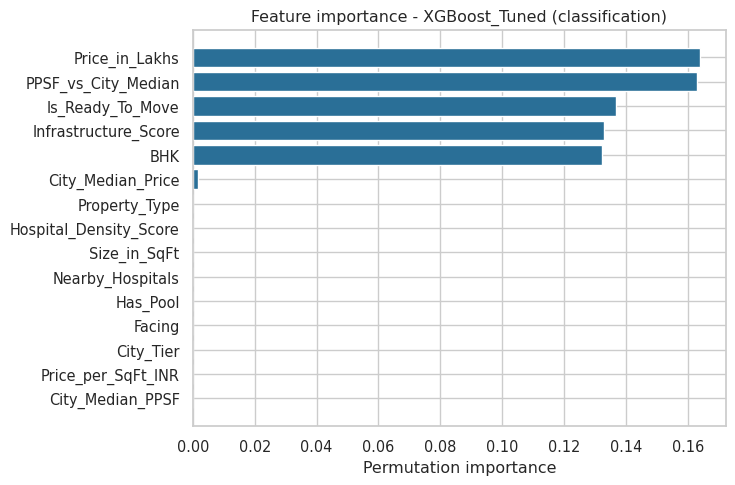

5-fold CV F1: 0.9990 +/- 0.0004


Ablation (no city-median features): accuracy 0.9986, F1 0.9987


In [15]:
imp_clf = grouped_importance(pipe_clf, Xte, yte, "f1")
plot_importance(imp_clf, f"Feature importance - {best_clf} (classification)")

# Stability check: 5-fold CV F1 on a 60k sample
s60 = tr.sample(60000, random_state=7)
cv = cross_val_score(make_pipeline(candidates[best_clf]), s60[ALL_FEATURES], s60[TARGET], cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="f1", n_jobs=1)
print(f"5-fold CV F1: {cv.mean():.4f} +/- {cv.std():.4f}")

# Ablation: drop city-median market-context features
abl_num = [c for c in NUM_FEATURES if c not in CONTEXT_FEATURES]
abl = make_pipeline(XGBClassifier(**best_xgb, tree_method="hist", n_jobs=1, random_state=RANDOM_STATE, eval_metric="logloss"), num_cols=abl_num).fit(tr[abl_num + CAT_FEATURES], ytr)
pa = abl.predict(te[abl_num + CAT_FEATURES])
print(f"Ablation (no city-median features): accuracy {accuracy_score(yte, pa):.4f}, F1 {f1_score(yte, pa):.4f}")

**Interpretation.** The label is a rule on the same features the model sees, so near-perfect scores confirm the model learned the intended logic (the top features are exactly the rule inputs). They are **not** evidence of real-world predictive accuracy. Logistic Regression (about 0.89 accuracy) cannot capture the threshold interactions that tree models do.

## 5. Regression: estimated price after 5 years

The target is modelled in **log space** (`TransformedTargetRegressor`), so predictions come back in lakhs. Two non-ML benchmarks are included: a flat 8% growth rate and tier-average growth. *Growth error* is the RMSE of the annual growth rate implied by each prediction (percentage points), a fairer measure than R², which is inflated by the price level.

In [16]:
TARGET_R = "Future_Price_5Y_Lakhs"
REG_NUM = NUM_FEATURES + ["Log_Price", "Log_Size"]; REG_FEATURES = REG_NUM + CAT_FEATURES
def reg_pipe(model): return make_pipeline(TransformedTargetRegressor(regressor=model, func=np.log, inverse_func=np.exp), num_cols=REG_NUM)

def reg_metrics(y, p, price, true_r, prefix):
    implied = (np.asarray(p) / np.asarray(price)) ** (1 / FORECAST_YEARS) - 1
    return {f"{prefix}_rmse": float(np.sqrt(mean_squared_error(y, p))), f"{prefix}_mae": float(mean_absolute_error(y, p)), f"{prefix}_r2": float(r2_score(y, p)),
            f"{prefix}_mape_pct": float(np.mean(np.abs((y - p) / y)) * 100), f"{prefix}_growth_rmse_pp": float(np.sqrt(np.mean((implied - true_r) ** 2)) * 100)}

rtr, rva, rte = split_data(df, TARGET_R)
get_experiment("RealEstate_Regression_FuturePrice5Y_NB", "regression")

tier_r = rtr.groupby("City_Tier")["Annual_Growth_Rate"].mean()
bench = {"Benchmark_Fixed8pct": rte["Fixed8_Future_Price_Lakhs"].values,
         "Benchmark_TierAvgGrowth": (rte["Price_in_Lakhs"] * (1 + rte["City_Tier"].map(tier_r)) ** FORECAST_YEARS).values}
reg_results = {}
for name, p in bench.items():
    with mlflow.start_run(run_name=name):
        m = reg_metrics(rte[TARGET_R].values, p, rte["Price_in_Lakhs"].values, rte["Annual_Growth_Rate"].values, "test")
        mlflow.log_metrics(m); mlflow.set_tag("task", "regression"); reg_results[name] = m

sub = rtr.sample(40000, random_state=RANDOM_STATE)
search = RandomizedSearchCV(reg_pipe(XGBRegressor(tree_method="hist", n_jobs=1, random_state=RANDOM_STATE)),
    {"model__regressor__n_estimators": [300, 500, 700], "model__regressor__max_depth": [3, 4, 6], "model__regressor__learning_rate": [0.05, 0.1, 0.2],
     "model__regressor__subsample": [0.8, 1.0], "model__regressor__colsample_bytree": [0.6, 0.8, 1.0], "model__regressor__min_child_weight": [1, 5]},
    n_iter=6, scoring="r2", cv=3, random_state=RANDOM_STATE, n_jobs=1).fit(sub[REG_FEATURES], sub[TARGET_R])
best_xgb_r = {k.replace("model__regressor__", ""): v for k, v in search.best_params_.items()}
print("Best XGB params:", best_xgb_r)

reg_candidates = {
    "LinearRegression_Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=10, max_features=0.5, n_jobs=1, random_state=RANDOM_STATE),
    "XGBoost_Tuned": XGBRegressor(**best_xgb_r, tree_method="hist", n_jobs=1, random_state=RANDOM_STATE)}
reg_fitted, reg_runs = {}, {}
for name, model in reg_candidates.items():
    with mlflow.start_run(run_name=name) as run:
        t0 = time.time(); pipe = reg_pipe(model).fit(rtr[REG_FEATURES], rtr[TARGET_R])
        m = {**reg_metrics(rva[TARGET_R].values, pipe.predict(rva[REG_FEATURES]), rva["Price_in_Lakhs"].values, rva["Annual_Growth_Rate"].values, "val"),
             **reg_metrics(rte[TARGET_R].values, pipe.predict(rte[REG_FEATURES]), rte["Price_in_Lakhs"].values, rte["Annual_Growth_Rate"].values, "test"), "fit_seconds": time.time() - t0}
        mlflow.log_params({"model": name, "target_transform": "log", "n_features": len(REG_FEATURES), "train_rows": len(rtr)}); mlflow.log_metrics(m); mlflow.set_tag("task", "regression")
        reg_results[name], reg_fitted[name], reg_runs[name] = m, pipe, run.info.run_id
pd.DataFrame(reg_results).T[["val_rmse", "test_rmse", "test_mae", "test_r2", "test_mape_pct", "test_growth_rmse_pp"]].round(4)

Best XGB params: {'subsample': 1.0, 'n_estimators': 700, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


,val_rmse,test_rmse,test_mae,test_r2,test_mape_pct,test_growth_rmse_pp
Benchmark_Fixed8pct,NaN,14.5786,10.3095,0.9952,2.7321,0.7304
Benchmark_TierAvgGrowth,NaN,11.5521,8.1283,0.9970,2.1627,0.5798
LinearRegression_Ridge,0.7986,0.7999,0.6241,1.0000,0.2221,0.0746
RandomForest,4.1191,4.0970,2.9597,0.9996,0.8912,0.2486
XGBoost_Tuned,1.2718,1.2715,1.0049,1.0000,0.4468,0.1757


Selected model (validation RMSE): LinearRegression_Ridge


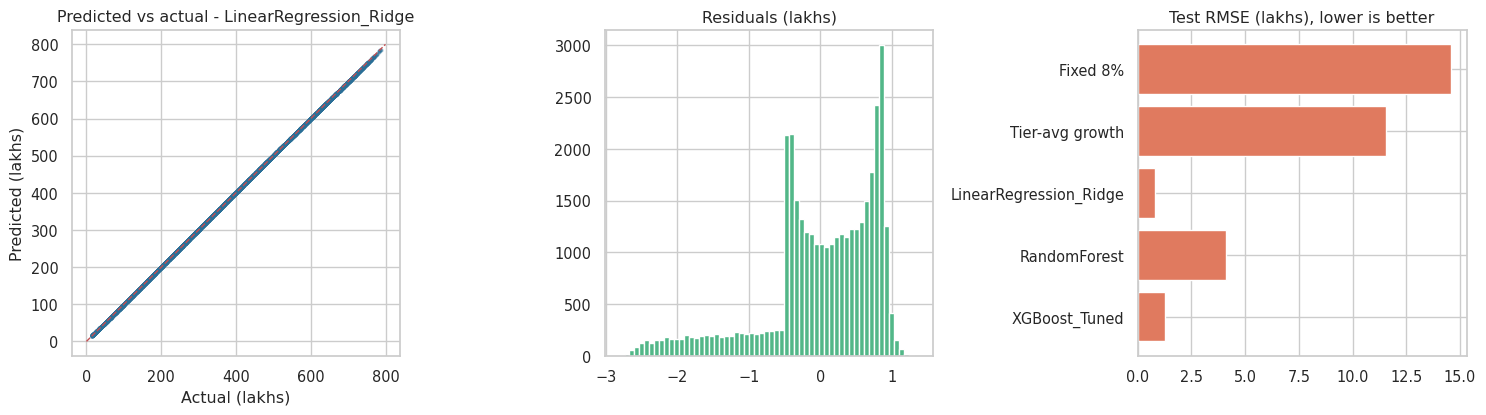

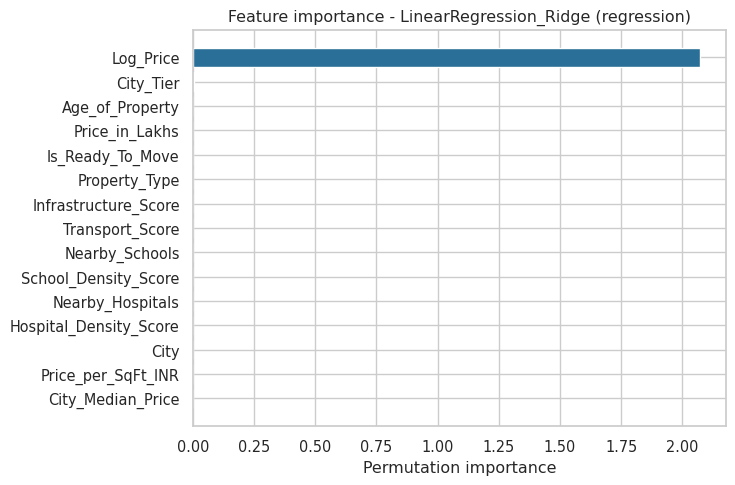

In [17]:
best_reg = min(reg_candidates, key=lambda k: reg_results[k]["val_rmse"]); pipe_reg = reg_fitted[best_reg]
print("Selected model (validation RMSE):", best_reg)
yt = rte[TARGET_R].values; pr = pipe_reg.predict(rte[REG_FEATURES])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3)); i = np.random.RandomState(0).choice(len(rte), 6000, replace=False)
ax[0].scatter(yt[i], pr[i], s=4, alpha=.35, color="#2a6f97"); ax[0].plot([0, yt.max()], [0, yt.max()], "r--", lw=1)
ax[0].set_title(f"Predicted vs actual - {best_reg}"); ax[0].set_xlabel("Actual (lakhs)"); ax[0].set_ylabel("Predicted (lakhs)")
ax[1].hist(pr - yt, bins=60, color="#52b788"); ax[1].set_title("Residuals (lakhs)")
names = ["Fixed 8%", "Tier-avg growth"] + list(reg_candidates)
rm = [reg_results["Benchmark_Fixed8pct"]["test_rmse"], reg_results["Benchmark_TierAvgGrowth"]["test_rmse"]] + [reg_results[k]["test_rmse"] for k in reg_candidates]
ax[2].barh(names[::-1], rm[::-1], color="#e07a5f"); ax[2].set_title("Test RMSE (lakhs), lower is better"); show()
imp_reg = grouped_importance(pipe_reg, rte[REG_FEATURES], rte[TARGET_R], "r2")
plot_importance(imp_reg, f"Feature importance - {best_reg} (regression)")

**Interpretation.** Because `log(Future) = log(Price) + 5·log(1+r)` and `r` is built from additive adjustments, a linear model in log space almost exactly matches the generating process, so Ridge wins on validation. As with classification, accuracy reflects the documented rules, not real-market forecasting skill.

## 6. MLflow: log and register the champion models

In [18]:
client = mlflow.MlflowClient()
def register(run_id, pipe, X, name):
    mlflow.set_experiment(experiment_id=client.get_run(run_id).info.experiment_id)
    with mlflow.start_run(run_id=run_id):
        mlflow.log_metrics({"champion": 1.0})
        mlflow.sklearn.log_model(pipe, name="model", signature=infer_signature(X.head(100), pipe.predict(X.head(100))), input_example=X.head(3),
                                 registered_model_name=name, serialization_format="cloudpickle")
    v = client.search_model_versions(f"name='{name}'")[0].version
    client.set_registered_model_alias(name, "champion", v); print(f"Registered {name} v{v} (alias: champion)")

register(clf_runs[best_clf], pipe_clf, Xte, "GoodInvestmentClassifier_NB")
register(reg_runs[best_reg], pipe_reg, rte[REG_FEATURES], "FuturePriceRegressor_NB")
joblib.dump(pipe_clf, MODELS_DIR / "good_investment_classifier.joblib", compress=3)
joblib.dump(pipe_reg, MODELS_DIR / "future_price_regressor.joblib", compress=3)
print("To browse runs:  mlflow ui --backend-store-uri sqlite:///mlflow/mlflow_notebook.db")

2026/10/25 17:18:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Successfully registered model 'GoodInvestmentClassifier_NB'.
Created version '1' of model 'GoodInvestmentClassifier_NB'.
2026/10/25 17:18:16 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Registered GoodInvestmentClassifier_NB v1 (alias: champion)


Registered FuturePriceRegressor_NB v1 (alias: champion)
To browse runs:  mlflow ui --backend-store-uri sqlite:///mlflow/mlflow_notebook.db


Successfully registered model 'FuturePriceRegressor_NB'.
Created version '1' of model 'FuturePriceRegressor_NB'.


## 7. Prediction for a new property

The function below turns one raw listing into model features (the same engineering as above) and returns the classification, confidence and 5-year price estimate. It is the piece the Streamlit app will call later.

In [19]:
lookups = {"city_median_ppsf": df.groupby("City")["Price_per_SqFt_INR"].median().to_dict(), "city_median_price": df.groupby("City")["Price_in_Lakhs"].median().to_dict(),
           "city_tier": df.groupby("City")["City_Tier"].first().to_dict(), "max_schools": int(df["Nearby_Schools"].max()), "max_hospitals": int(df["Nearby_Hospitals"].max())}

def predict_property(p):
    amen = {a.strip() for a in p.get("Amenities", "").split(",") if a.strip()}
    size, price, bhk = p["Size_in_SqFt"], p["Price_in_Lakhs"], p["BHK"]; floors = max(p["Total_Floors"], p["Floor_No"]); ppsf = price * 1e5 / size
    tr_ = TRANSPORT_MAP[p["Public_Transport_Accessibility"]]; sc = p["Nearby_Schools"] / lookups["max_schools"]; ho = p["Nearby_Hospitals"] / lookups["max_hospitals"]; c = p["City"]
    row = {"BHK": bhk, "Size_in_SqFt": size, "Price_in_Lakhs": price, "Price_per_SqFt_INR": ppsf, "Age_of_Property": REFERENCE_YEAR - p["Year_Built"],
           "Floor_No": p["Floor_No"], "Total_Floors": floors, "Floor_Ratio": p["Floor_No"] / floors, "Nearby_Schools": p["Nearby_Schools"], "Nearby_Hospitals": p["Nearby_Hospitals"],
           "Transport_Score": tr_, "School_Density_Score": sc, "Hospital_Density_Score": ho, "Infrastructure_Score": (sc + ho + tr_) / 3, "Amenity_Count": len(amen),
           **{f"Has_{a}": int(a in amen) for a in ["Gym", "Pool", "Clubhouse", "Playground", "Garden"]}, "Has_Parking": int(p["Parking_Space"] == "Yes"),
           "Has_Security": int(p["Security"] == "Yes"), "Is_Ready_To_Move": int(p["Availability_Status"] == "Ready_to_Move"), "SqFt_per_BHK": size / bhk,
           "City_Median_PPSF": lookups["city_median_ppsf"][c], "City_Median_Price": lookups["city_median_price"][c], "PPSF_vs_City_Median": ppsf / lookups["city_median_ppsf"][c],
           "Log_Price": np.log1p(price), "Log_Size": np.log1p(size), "Property_Type": p["Property_Type"], "Furnished_Status": p["Furnished_Status"], "Facing": p["Facing"],
           "Owner_Type": p["Owner_Type"], "City": c, "City_Tier": lookups["city_tier"][c]}
    X = pd.DataFrame([row]); prob = float(pipe_clf.predict_proba(X[ALL_FEATURES])[0, 1]); fut = float(pipe_reg.predict(X[REG_FEATURES])[0])
    return {"good_investment": prob >= 0.5, "confidence": round(max(prob, 1 - prob), 4), "current_price_lakhs": price, "future_price_5y_lakhs": round(fut, 2),
            "implied_annual_growth_pct": round(((fut / price) ** (1 / FORECAST_YEARS) - 1) * 100, 2), "expected_gain_lakhs": round(fut - price, 2)}

example = {"City": "Pune", "Property_Type": "Apartment", "BHK": 3, "Size_in_SqFt": 1800, "Price_in_Lakhs": 120, "Year_Built": 2018, "Furnished_Status": "Semi-furnished",
           "Floor_No": 8, "Total_Floors": 15, "Nearby_Schools": 8, "Nearby_Hospitals": 6, "Public_Transport_Accessibility": "High", "Parking_Space": "Yes", "Security": "Yes",
           "Amenities": "Gym, Pool, Garden", "Facing": "East", "Owner_Type": "Builder", "Availability_Status": "Ready_to_Move"}
predict_property(example)

{'good_investment': True,
 'confidence': 1.0,
 'current_price_lakhs': 120,
 'future_price_5y_lakhs': 179.32,
 'implied_annual_growth_pct': 8.36,
 'expected_gain_lakhs': 59.32}

## 8. Conclusions and limitations

| Task | Selected model | Test result |
|---|---|---|
| Good Investment | XGBoost (tuned) | accuracy ≈ 99.95%, F1 ≈ 0.9996 |
| Price after 5 years | Ridge (log target) | RMSE ≈ 0.80 lakhs, R² ≈ 1.000 |

**Limitations (please read):**
- Both targets are **rule-derived** because the dataset has no price history; near-perfect scores show the pipeline learns the documented rules, not real-market accuracy.
- Growth rates are assumptions (see the config cell); replace them with estimates from historical data when available.
- Price is nearly independent of every feature in this dataset, so EDA shows few real relationships; there is no crime-rate field.
- `Locality` repeats across all cities and was not modelled.

**Next steps:** historical price data, back-testing of the investment rule, prediction intervals, and the Streamlit application built on `predict_property`.

## 9. Streamlit application and compatibility verification

The packaged app now uses a premium obsidian-and-mint theme while preserving the original Talina/Manrope typography. Procedural 3D buildings and the geographic column map have been replaced by a premium architectural visual and an interactive Market Atlas. Insights includes a custom opportunity index, connectivity Sankey diagram, amenity analysis and filtered CSV export.

Run the app from the project root:

```bash
python -m pip install -r app/requirements.txt
streamlit run app/app.py
```

The app inference classifier is a portable HistGradientBoosting model distilled from the five deterministic investment criteria. The original XGBoost research model and held-out metrics remain preserved separately.

The next cell performs a model-load and single-property prediction smoke test against the exact artifacts used by the app.

In [ ]:
APP_DIR = ROOT / "app"
assert (APP_DIR / "app.py").exists(), "app/app.py is missing"
sys.path.insert(0, str(APP_DIR)) if str(APP_DIR) not in sys.path else None
from core import predictor

sample_property = {
    "City": "Pune", "Property_Type": "Apartment", "BHK": 3,
    "Size_in_SqFt": 1800, "Price_in_Lakhs": 120.0, "Year_Built": 2018,
    "Furnished_Status": "Semi-furnished", "Floor_No": 8, "Total_Floors": 15,
    "Nearby_Schools": 8, "Nearby_Hospitals": 6,
    "Public_Transport_Accessibility": "High", "Parking_Space": "Yes",
    "Security": "Yes", "Amenities": "Gym, Pool, Garden", "Facing": "East",
    "Owner_Type": "Builder", "Availability_Status": "Ready_to_Move",
}
result = predictor.predict(sample_property)
assert 0 <= result["prob"] <= 1
assert result["future"] > 0 and result["met"] in range(6)
print({
    "good_investment": result["good"],
    "probability": round(result["prob"], 4),
    "five_year_price_lakhs": round(result["future"], 2),
    "implied_annual_growth_pct": round(result["growth"] * 100, 2),
    "criteria_met": result["met"],
})
print("Model loading and app prediction smoke test passed.")